In [1]:
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm

from Dataflux.pytorch import Dataset
from Comprisk.anomaly import AnomalyDetector, AnomalyDetectionMethod

In [2]:
path = "models/AutoEncoder/outlier-removed-nobypass/version_0/config.yaml"

# the 'orange' labeled dataset should have outliers between 1st April and 27th April
#                                                           1st July and 17th July
dataset = Dataset("/Users/jonas/Dataset/labeled/dataset-cat-orange", 500, 500, 20)

/Users/jonas/.miniconda/envs/comprisk/lib/python3.12/site-packages/lightning/fabric/utilities/cloud_io.py:57: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
100%|██████████| 156/156 [00:08<00

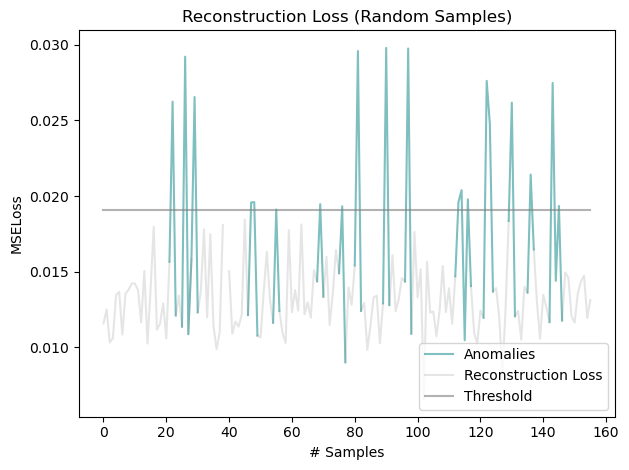

In [5]:
detector = AnomalyDetector(path, detection_method=AnomalyDetectionMethod.MEAN)
detector.train_threshold(dataset, limit_samples=5_000, visualize=True)

# following line is just for demonstration
detector.set_threshold(detector.threshold)

100%|██████████| 144/144 [00:03<00:00, 44.09it/s]


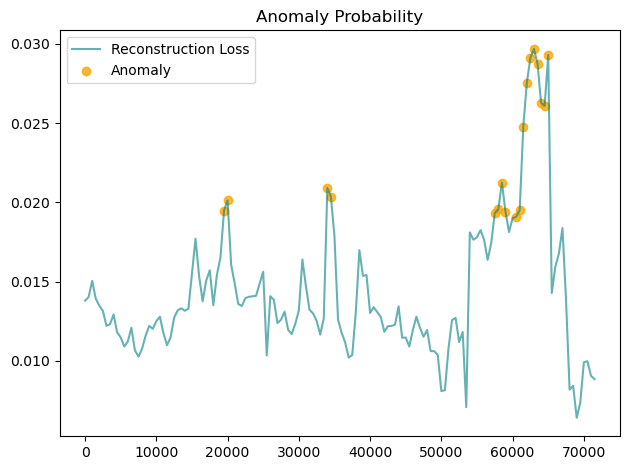

In [7]:
sliding = dataset.get_meta().num_input_sequence
start_at = 0
samples = len(dataset) // dataset.get_meta().num_input_sequence
limit_training = start_at + samples * sliding

losses = [[], []]
detected = [[], []]
temp_weather = [[], []]
for i in tqdm(range(start_at, limit_training, sliding)):
    sensors, weather, _ = dataset[i]
    temp_weather[1].append(weather[0])
    temp_weather[0].append(i)
    anomaly, loss = detector.is_anomaly({"sensors": sensors, "weather": weather}, True)
    losses[1].append(loss)
    losses[0].append(i)
    if anomaly:
        detected[0].append(i)
        detected[1].append(loss)

plt.title("Anomaly Probability")
plt.plot(losses[0], losses[1], color="teal", alpha=0.6, label="Reconstruction Loss")
#plt.plot(temp_weather[0], temp_weather[1], color="teal", alpha=0.3, label="Weather")
plt.scatter(detected[0], detected[1], color="orange", alpha=0.8, label="Anomaly")
plt.legend()
plt.show()

In [25]:
def plot_idx(idx, reverse: bool = False, width: int = 10_000):
    import math
    # get the loss per sensor
    sensors, weather, _ = dataset[idx]
    loss_per_feature = detector.detect({"sensors": sensors, "weather": weather}, feature=True)
    loss_per_feature = [(key, i, loss_per_feature[i]) for i, key in enumerate(dataset.get_meta().column_names_sensor)]
    loss_per_feature = sorted(loss_per_feature, key=lambda x: x[-1], reverse=reverse)

    # sample the original data
    window_length = dataset.get_meta().num_input_sequence
    data, anomaly, reconstruct, rec_anomaly = [], None, [], None
    start, end = idx - (width // 2), idx + (width // 2)
    for i in range(start, end, window_length):
        sensors, weather, _ = dataset[i]
        rec = detector.reconstruction({"sensors": sensors, "weather": weather})[0]

        if i != idx:
            data += list(sensors)
            reconstruct += list(rec)
        else:
            anomaly = sensors
            rec_anomaly = rec
            data += list(np.nan * np.ones_like(sensors))
            reconstruct += list(np.nan * np.ones_like(sensors))

    data = np.array(data)
    reconstruct = np.array(reconstruct)

    num_sensors = 26
    rows = math.ceil(num_sensors / 5)
    fig, axs = plt.subplots(rows, 5, figsize=(5 * 5, 5 * (rows - 1)))
    if num_sensors < 5:
        axs = [axs]
    for sensor in range(num_sensors):
        i = loss_per_feature[sensor][1]
        #print("Anomaly:", loss_per_feature[sensor][0], round(float(loss_per_feature[sensor][2]), 4), "idx=", idx)

        axs[math.floor(sensor / 5)][sensor % 5].plot(np.linspace(start, end, len(data)), data[:, i], label="Data", color="teal", alpha=0.3)
        axs[math.floor(sensor / 5)][sensor % 5].plot(np.linspace(idx, idx + window_length, len(anomaly)), anomaly[:, i], label="Anomaly", color="teal", alpha=0.9)

        axs[math.floor(sensor / 5)][sensor % 5].plot(np.linspace(start, end, len(reconstruct)), reconstruct[:, i], label="Reconstruct", color="orange", alpha=0.3)
        axs[math.floor(sensor / 5)][sensor % 5].plot(np.linspace(idx, idx + window_length, len(rec_anomaly)), rec_anomaly[:, i], label="Reconstruct", color="orange", alpha=0.9)

        if reverse:
            axs[math.floor(sensor / 5)][sensor % 5].set_title(f"({num_sensors - sensor}) " + loss_per_feature[sensor][0])
        else:
            axs[math.floor(sensor / 5)][sensor % 5].set_title(f"({1 + sensor}) " + loss_per_feature[sensor][0])

    title_pre = "Best 5" if not reverse else "Worst 5"
    fig.suptitle(f"{title_pre} Feature Reconstruction")
    plt.legend()
    plt.show()

In [26]:
_detected = np.array(detected)
_detected = sorted([ _ for _ in zip(_detected[0], _detected[1])], key=lambda x: x[1], reverse=True)
if len(_detected) > 0:
    idx = int(_detected[0][0])
    day, hour = dataset.get_day(idx)
    day, hour, _detected[0][1], idx
else:
    idx = np.argmax(losses[1]) * sliding

print("Date\t\t Index\t\t Loss")
print("=" * 55)
for i in range(len(_detected)):
    _idx, _loss = _detected[i]
    day, hour = dataset.get_day(_idx)
    print(day, "\t", _idx, "\t", _loss)


Date		 Index		 Loss
2023-07-03_1 	 63000.0 	 0.02968629077076912
2023-07-03_1 	 65000.0 	 0.029292184859514236
2023-07-03_1 	 62500.0 	 0.02912495657801628
2023-07-03_1 	 63500.0 	 0.02874402515590191
2023-07-03_1 	 62000.0 	 0.02753734402358532
2023-07-03_1 	 64000.0 	 0.026274293661117554
2023-07-03_1 	 64500.0 	 0.026097772642970085
2023-07-03 	 61500.0 	 0.024766016751527786
2023-07-01 	 58500.0 	 0.02124927192926407
2023-04-20 	 34000.0 	 0.020907528698444366
2023-04-20 	 34500.0 	 0.02035963162779808
2023-04-01 	 20000.0 	 0.020119082182645798
2023-07-01 	 58000.0 	 0.019560208544135094
2023-07-01 	 61000.0 	 0.019517431035637856
2023-04-01 	 19500.0 	 0.019469410181045532
2023-07-01 	 59000.0 	 0.019415412098169327
2023-07-01 	 57500.0 	 0.01931864023208618
2023-07-01 	 60500.0 	 0.019085252657532692


/var/folders/ts/r3hrcxvd0cx72858g2kkg6p80000gn/T/ipykernel_30517/1524716333.py:51: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


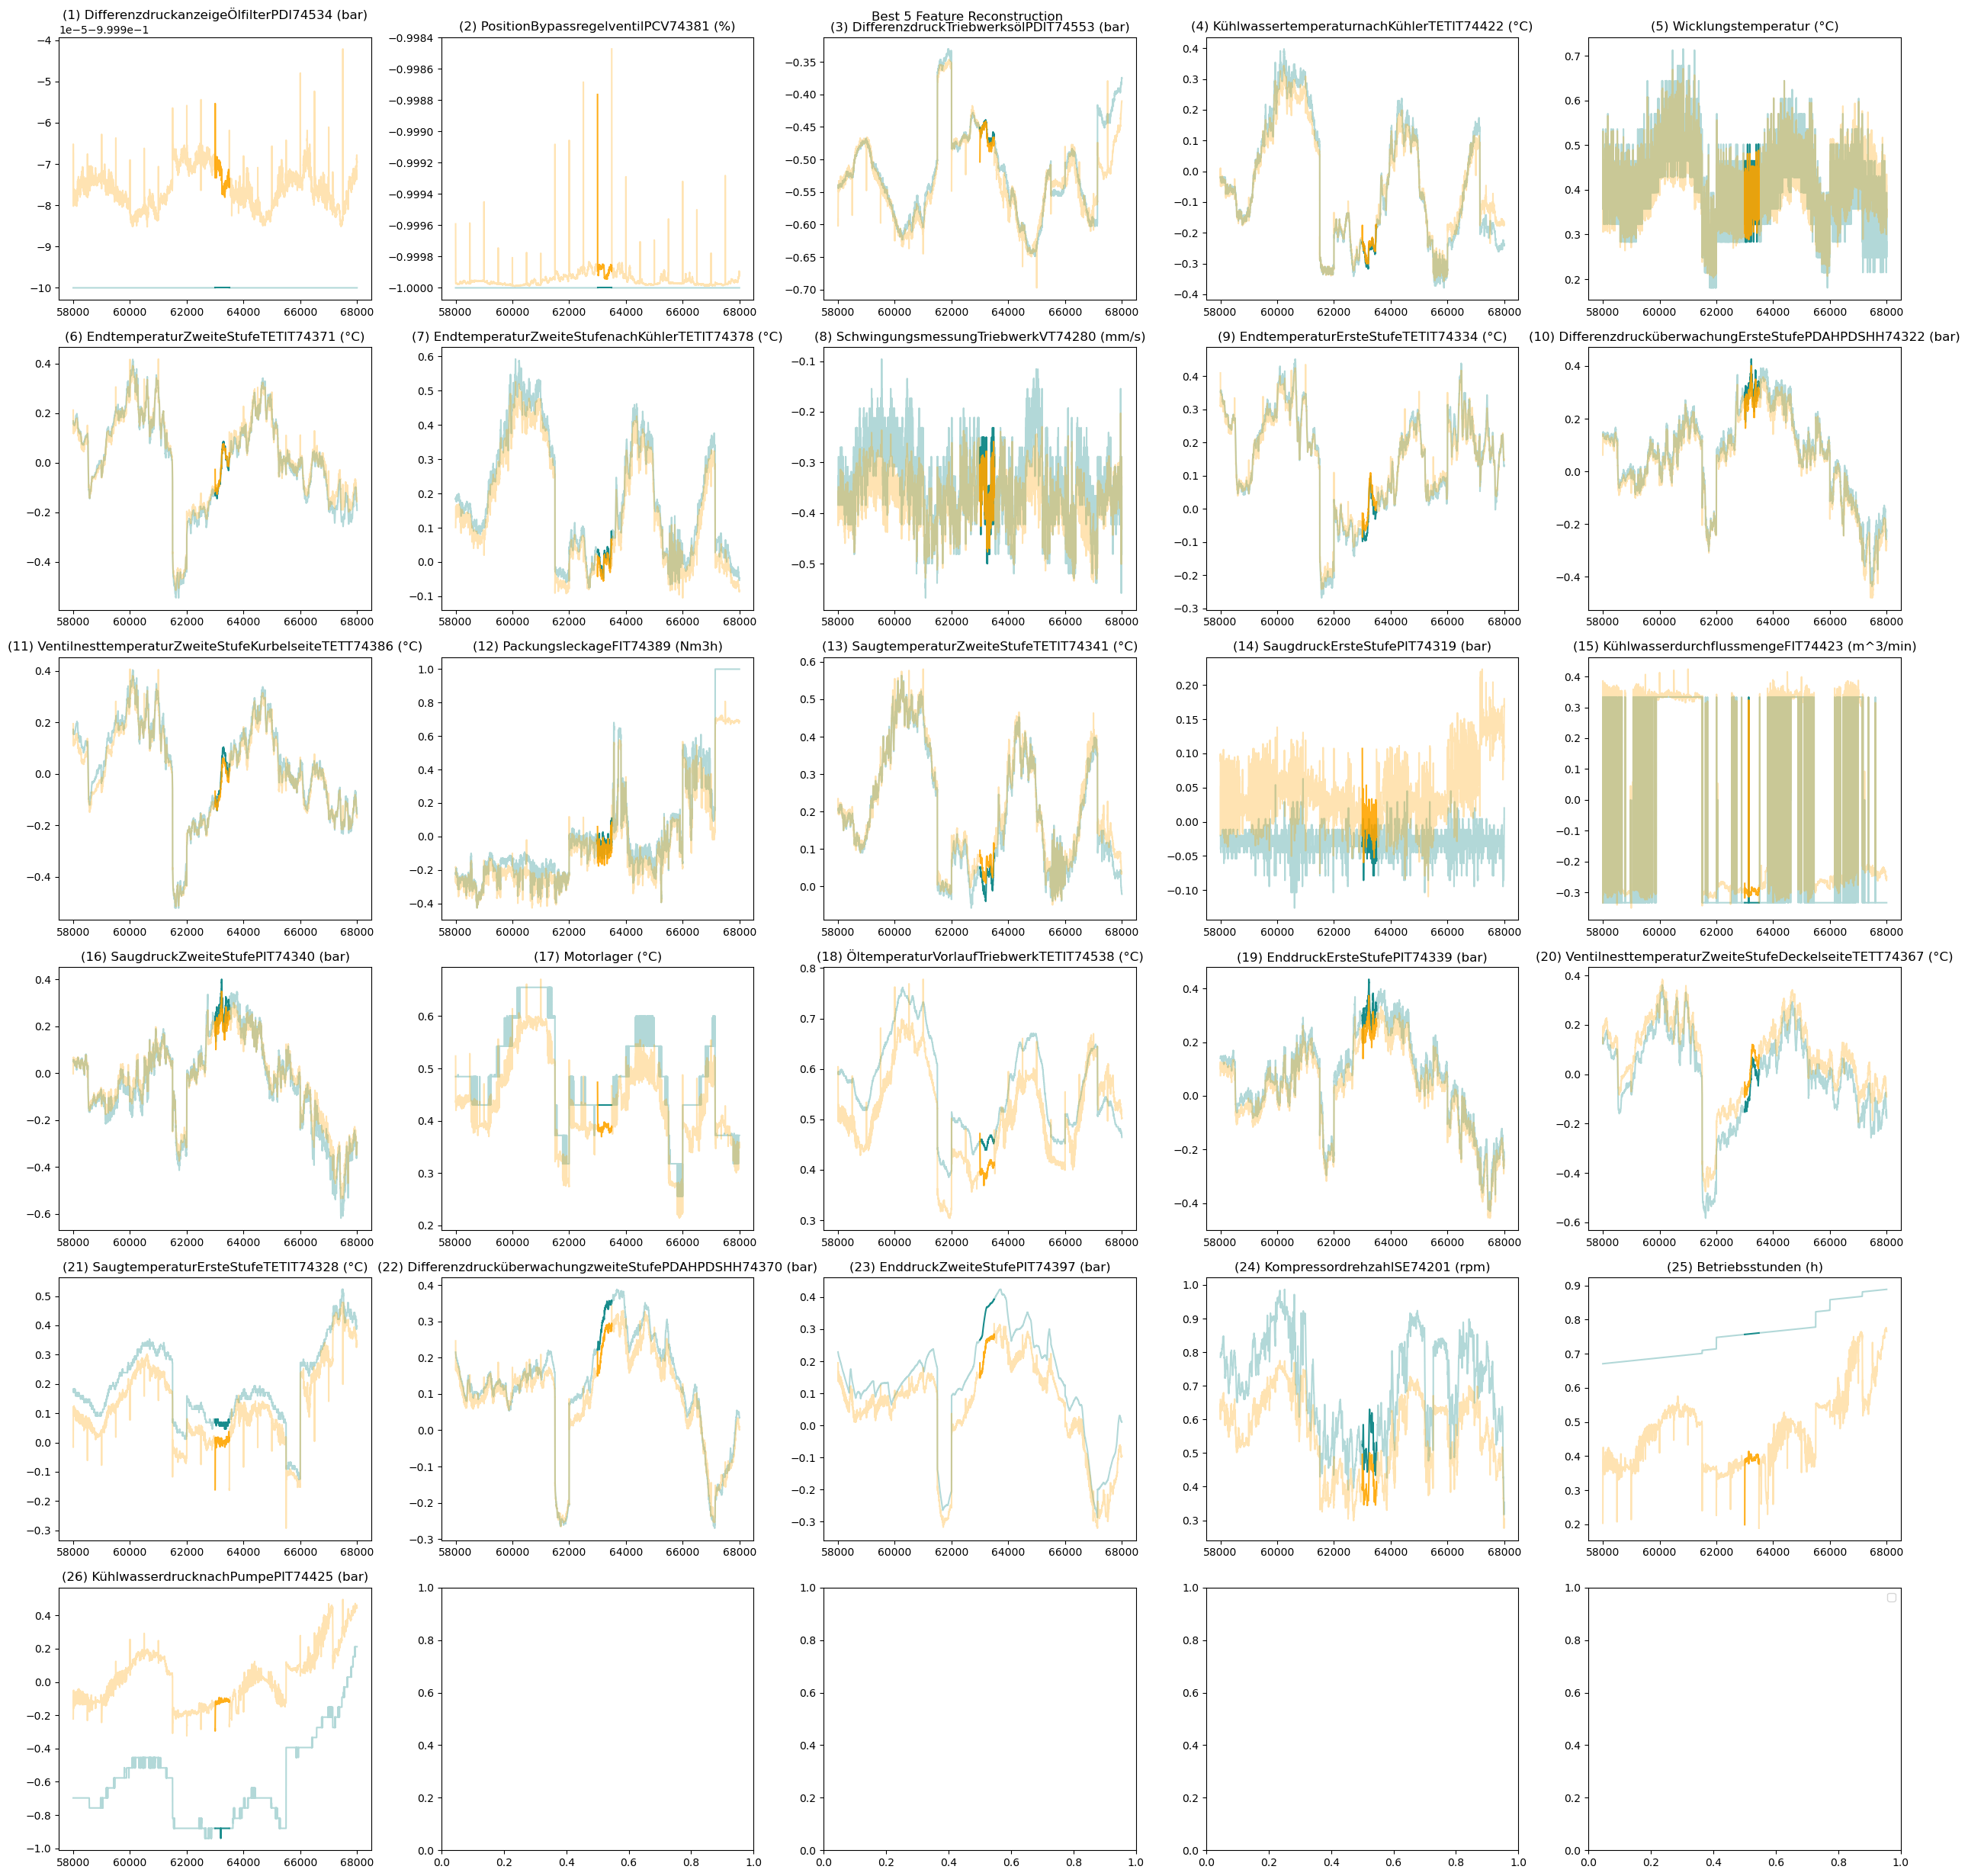

[('DifferenzdruckanzeigeÖlfilterPDI74534 (bar)', 2, 7.2395745e-10), ('PositionBypassregelventilPCV74381 (%)', 16, 1.616424e-08), ('DifferenzdruckTriebwerksölPDIT74553 (bar)', 1, 5.228893e-05), ('KühlwassertemperaturnachKühlerTETIT74422 (°C)', 13, 9.275069e-05), ('Wicklungstemperatur (°C)', 24, 0.000114440576), ('EndtemperaturZweiteStufeTETIT74371 (°C)', 8, 0.00013666695), ('EndtemperaturZweiteStufenachKühlerTETIT74378 (°C)', 9, 0.00027533827), ('SchwingungsmessungTriebwerkVT74280 (mm/s)', 21, 0.00032267268), ('EndtemperaturErsteStufeTETIT74334 (°C)', 7, 0.00058081886), ('DifferenzdrucküberwachungErsteStufePDAHPDSHH74322 (bar)', 3, 0.0007246099), ('VentilnesttemperaturZweiteStufeKurbelseiteTETT74386 (°C)', 23, 0.00072948023), ('PackungsleckageFIT74389 (Nm3h)', 15, 0.0011493472), ('SaugtemperaturZweiteStufeTETIT74341 (°C)', 20, 0.0011769319), ('SaugdruckErsteStufePIT74319 (bar)', 17, 0.0011919186), ('KühlwasserdurchflussmengeFIT74423 (m^3/min)', 12, 0.0012685375), ('SaugdruckZweiteStufeP

In [27]:
plot_idx(idx)

In [48]:
sensors, weather, _ = dataset[idx]
in_mean = sensors

predicted = detector.reconstruction({"sensors": sensors, "weather": weather}, True)[0]
out_mean = predicted

error = np.power(predicted - sensors, 2).mean(0)

temp = [(i, v) for i, v in enumerate(dataset.get_meta().column_names_sensor)]
info = [(v[0], error[v[0]], v[1]) for v in temp]
info = sorted(info, key=lambda x: x[1], reverse=True)

print("Sensor\t Anomaly Prob.\t Description")
print("-" * 55)
for i in range(len(info)):
    print(info[i][0], "\t", f"{round(info[i][1] * 100, 2)}%", "\t\t", info[i][2])

Sensor	 Anomaly Prob.	 Description
-------------------------------------------------------
11 	 58.38% 		 KühlwasserdrucknachPumpePIT74425 (bar)
0 	 13.39% 		 Betriebsstunden (h)
10 	 1.29% 		 KompressordrehzahlSE74201 (rpm)
6 	 1.16% 		 EnddruckZweiteStufePIT74397 (bar)
4 	 0.4% 		 DifferenzdrucküberwachungzweiteStufePDAHPDSHH74370 (bar)
19 	 0.38% 		 SaugtemperaturErsteStufeTETIT74328 (°C)
22 	 0.37% 		 VentilnesttemperaturZweiteStufeDeckelseiteTETT74367 (°C)
5 	 0.36% 		 EnddruckErsteStufePIT74339 (bar)
25 	 0.3% 		 ÖltemperaturVorlaufTriebwerkTETIT74538 (°C)
14 	 0.19% 		 Motorlager (°C)
18 	 0.17% 		 SaugdruckZweiteStufePIT74340 (bar)
12 	 0.13% 		 KühlwasserdurchflussmengeFIT74423 (m^3/min)
17 	 0.12% 		 SaugdruckErsteStufePIT74319 (bar)
20 	 0.12% 		 SaugtemperaturZweiteStufeTETIT74341 (°C)
15 	 0.11% 		 PackungsleckageFIT74389 (Nm3h)
23 	 0.07% 		 VentilnesttemperaturZweiteStufeKurbelseiteTETT74386 (°C)
3 	 0.07% 		 DifferenzdrucküberwachungErsteStufePDAHPDSHH74322 (bar)
7 	 0.